# Chest X Ray Classification: Modified Implementation Platform, Round 2 (Fine Tuning)

**Round 2 question.** Frozen ImageNet features may carry too little disease detail inside the lungs. If the last convolution block of VGG19 is trained together with the classifier, can lung guidance teach the network to find disease patterns inside the lungs?

**What changes in the modified block (`train.py`).**

1. **Fine tuning.** VGG19's last convolution block (block 5) is trained along with the grid classifier. Blocks 1 to 4 stay frozen, so their output is computed once and reused.
2. **A stricter penalty.** A trainable block could move outside information into the lung cells, where the round 1 penalty would not see it. The penalty is therefore measured on the input of block 5. For every location of that 14 by 14 input, attribution is the gradient of the correct class's log probability times the input. The penalty is the share of attribution that falls outside the lungs.
3. **Source weights** stay available as a second switch, exactly as in round 1.

**Same data split as round 1.** The split is rebuilt with the same seed and checked against the round 1 counts. The penalty strength is chosen on the test set, by a rule fixed before the run.

**Note on the unseen set.** The unseen set was opened once in round 1, and round 2 was designed after seeing those results. No setting in this notebook is chosen with the unseen images, and Section 9 is a second look at them.

## 1. Setup

In [1]:
# Removes files from earlier runs so every run starts clean. The dataset zip file is kept to avoid a second download.
%cd /content
!rm -rf covid_pneumonia_dataset covid_pneumonia_dataset_wrapped pyimagesearch-covid19-image-classification lung_data xray_platform week11_split.csv
#!rm -f covid_pneumonia_dataset.zip

/content


In [2]:
# Clones the project repository, which holds lung_focus.py, the script that runs the second parent paper's lung finder.
REPO = "/content/pyimagesearch-covid19-image-classification"
!git clone -q https://github.com/MarzSaod/pyimagesearch-covid19-image-classification {REPO}
!ls {REPO}

build_covid_dataset.py	models			 Readme.md
dataset			notebook_images		 report_utils.py
lung_focus.py		original-keras-covid-19  sample_kaggle_dataset.py
model_performance	predict_covid19.py	 train_covid19.py


In [3]:
# Downloads the dataset (Asraf and Islam, Mendeley Data, version 2) and extracts it into a fresh folder.
import os, shutil, zipfile
%cd /content
ZIP = "covid_pneumonia_dataset.zip"
if not (os.path.exists(ZIP) and zipfile.is_zipfile(ZIP)):
    !wget -q -O {ZIP} "https://data.mendeley.com/public-api/zip/mxc6vb7svm/download/2"
shutil.rmtree("covid_pneumonia_dataset", ignore_errors=True)
with zipfile.ZipFile(ZIP) as z:
    z.extractall("covid_pneumonia_dataset")
for item in os.listdir("covid_pneumonia_dataset"):
    if item.endswith(".zip"):
        inner = os.path.join("covid_pneumonia_dataset", item)
        with zipfile.ZipFile(inner) as z:
            z.extractall("covid_pneumonia_dataset")
        os.remove(inner)

DATASET = "/content/covid_pneumonia_dataset_wrapped/all"
shutil.rmtree(DATASET, ignore_errors=True)
os.makedirs(DATASET)
for c in ["covid", "normal", "pneumonia"]:
    shutil.copytree(f"/content/covid_pneumonia_dataset/{c}", f"{DATASET}/{c}")
print("Dataset folder:", DATASET)

/content
Dataset folder: /content/covid_pneumonia_dataset_wrapped/all


In [4]:
# Confirms that a GPU is available.
import tensorflow as tf, torch
print("TensorFlow", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))
print("PyTorch", torch.__version__, "| CUDA:", torch.cuda.is_available())
for g in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError:
        pass

TensorFlow 2.21.0 | GPUs: 1
PyTorch 2.14.1+cu130 | CUDA: True


In [5]:
# Settings for the whole run.
CONFIG = dict(
    classes=["covid", "normal", "pneumonia"],
    image_size=224,
    weights="imagenet",
    split_seed=42,
    split=dict(train=0.70, test=0.15, unseen=0.15),
    head_epochs=30,                 # stage 1: grid classifier on frozen features (same as round 1)
    batch=64,
    seeds=[0, 1, 2],
    finetune=dict(epochs=8, lr=3e-5),   # stage 2: block 5 and the classifier together, best epoch by test loss
    lambdas=[1, 5],                 # penalty strengths tried on the test set
    sweep_seed=10,
    max_accuracy_drop=0.03,         # rule: among strengths within 3 points of the fine tuned baseline's test accuracy, keep the highest test PNG AUC
    round1_lambda=0.5,              # strength chosen for VGG19 in round 1
    bootstrap=1000,
)

# Split counts from round 1, used to confirm that the same split is rebuilt.
ROUND1_SPLIT = {"train": 4857, "test": 1041, "unseen": 1041}
ROUND1_TRAIN = {"covid, PNG collection": 1, "covid, JPEG collection": 136, "covid, other files": 1482,
                "normal, PNG collection": 1384, "normal, JPEG collection": 236,
                "pneumonia, PNG collection": 123, "pneumonia, JPEG collection": 1495}

# Round 1 results for VGG19 on the unseen set (mean over 3 seeds), for the final comparison.
ROUND1_UNSEEN_VGG19 = {
    "frozen baseline (round 1)": {"accuracy": 94.4, "pneumonia recall, PNG": 9.9, "normal recall, JPEG": 89.3, "normal vs pneumonia AUC, PNG": 0.656, "Grad CAM heat inside lungs": 23.3},
    "frozen source weights (round 1)": {"accuracy": 92.6, "pneumonia recall, PNG": 24.7, "normal recall, JPEG": 90.7, "normal vs pneumonia AUC, PNG": 0.646, "Grad CAM heat inside lungs": 23.1},
    "frozen lung guided (round 1)": {"accuracy": 93.1, "pneumonia recall, PNG": 4.9, "normal recall, JPEG": 88.0, "normal vs pneumonia AUC, PNG": 0.586, "Grad CAM heat inside lungs": 56.2},
    "frozen lung guided + source weights (round 1)": {"accuracy": 92.0, "pneumonia recall, PNG": 19.8, "normal recall, JPEG": 92.7, "normal vs pneumonia AUC, PNG": 0.644, "Grad CAM heat inside lungs": 45.1},
}

## 2. Pipeline modules

`train.py` is the modified block. Round 2 adds `fine_tune_guided`, `predict_finetuned`, and `attribution_outside` to it, and `models.py` gains the fine tuning model.

In [6]:
!mkdir -p /content/xray_platform

In [7]:
%%writefile /content/xray_platform/__init__.py
"""Modular pipeline for three class chest X ray classification (normal, pneumonia, covid)."""

Writing /content/xray_platform/__init__.py


In [8]:
%%writefile /content/xray_platform/data.py
"""Dataset listing, image loading, and split plans."""
import os
import re
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd

IMAGE_EXTS = (".png", ".jpg", ".jpeg", ".jfif", ".bmp")


def list_images(root, classes):
    """Lists images in root/<class>/ (top level only), sorted by class then file name."""
    paths, labels = [], []
    for ci, c in enumerate(classes):
        folder = os.path.join(root, c)
        names = sorted(n for n in os.listdir(folder) if n.lower().endswith(IMAGE_EXTS))
        paths += [os.path.join(folder, n) for n in names]
        labels += [ci] * len(names)
    return np.array(paths), np.array(labels)


def count_table(paths, labels, classes):
    exts = pd.Series([os.path.splitext(p)[1].lower() for p in paths])
    t = pd.crosstab(exts.rename("file type"), pd.Series([classes[l] for l in labels], name="class"))
    t.loc["total"] = t.sum()
    return t


def read_rgb(path, size):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        from PIL import Image
        img = np.array(Image.open(path).convert("RGB"))
    else:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)


def load_images(paths, size, workers=8):
    """Loads every image as uint8 RGB at size x size."""
    out = np.zeros((len(paths), size, size, 3), np.uint8)
    with ThreadPoolExecutor(workers) as ex:
        for i, img in enumerate(ex.map(lambda p: read_rgb(p, size), paths)):
            out[i] = img
    return out


def kfold_plan(labels, k, val_frac, seed):
    """Stratified k fold plan. Each fold tests on 1/k of the data and keeps val_frac of the rest for validation."""
    from sklearn.model_selection import StratifiedKFold, train_test_split

    folds = []
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    for f, (trval, test) in enumerate(skf.split(np.zeros(len(labels)), labels)):
        tr, va = train_test_split(trval, test_size=val_frac, stratify=labels[trval], random_state=seed + f)
        folds.append((np.sort(tr), np.sort(va), np.sort(test)))
    return folds


def plan_table(folds, labels, classes):
    rows = []
    for f, parts in enumerate(folds):
        for name, ix in zip(("train", "validation", "test"), parts):
            row = {"fold": f + 1, "set": name, "images": len(ix)}
            row.update({c: int((labels[ix] == i).sum()) for i, c in enumerate(classes)})
            rows.append(row)
    return pd.DataFrame(rows).set_index(["fold", "set"])


def file_properties(paths):
    """Properties of each file that say nothing about the lungs: file type, original width and height, color mode, and file size."""
    from PIL import Image

    def one(p):
        with Image.open(p) as im:
            w, h, mode = im.size[0], im.size[1], im.mode
        return {"type": os.path.splitext(p)[1].lower(), "width": w, "height": h, "mode": mode, "kilobytes": os.path.getsize(p) / 1024}

    with ThreadPoolExecutor(16) as ex:
        table = pd.DataFrame(list(ex.map(one, paths)))
    return table


def encode_properties(table):
    """Turns the property table into numbers for a classifier."""
    return pd.get_dummies(table, columns=["type", "mode"], dtype=float).to_numpy(np.float32)


# Where each image came from. The dataset joins several public collections, and file type plus size identify them.
COLLECTIONS = ("PNG collection", "JPEG collection", "other files")


def collections(props):
    """PNG files of 1024 by 1024 pixels, JPEG files of any other size, and everything else."""
    big = (props["width"].values == 1024) & (props["height"].values == 1024)
    kind = props["type"].values
    return np.where((kind == ".png") & big, COLLECTIONS[0],
                    np.where((kind == ".jpeg") & ~big, COLLECTIONS[1], COLLECTIONS[2]))


def collection_table(coll, labels, classes):
    t = pd.crosstab(pd.Series(coll, name="collection"), pd.Series([classes[l] for l in labels], name="class"))
    t = t.reindex([c for c in COLLECTIONS if c in t.index])
    t.loc["total"] = t.sum()
    return t


# Groups of images that must stay on the same side of every split: near copies and images of the same patient.
PATIENT_PATTERNS = [
    (re.compile(r"^(\d{8})_\d{3}$"), "nih"),
    (re.compile(r"^person(\d+)_(?:bacteria|virus)_\d+$", re.I), "kp"),
    (re.compile(r"^((?:normal2-)?im-\d{4})-\d{4}(?:-\d{4})?$", re.I), "kn"),
]


def patient_keys(paths):
    keys = []
    for p in paths:
        stem, key = os.path.splitext(os.path.basename(p))[0], ""
        for pat, tag in PATIENT_PATTERNS:
            m = pat.match(stem)
            if m:
                key = tag + ":" + m.group(1).lower()
                break
        keys.append(key)
    return np.array(keys)


def near_copy_pairs(images, bar_start=0.98, max_group=None):
    """Pairs of images whose 32 by 32 gray thumbnails correlate at the bar or more, also after mirroring one of them.
    If one very large group forms, the bar is raised until groups are small again."""
    from scipy.sparse import coo_matrix
    from scipy.sparse.csgraph import connected_components

    n = len(images)
    max_group = max_group or max(20, int(0.005 * n))
    thumbs = np.stack([cv2.resize(im[..., 0], (32, 32), interpolation=cv2.INTER_AREA) for im in images])

    def norm(t):
        x = t.reshape(len(t), -1).astype(np.float32)
        x -= x.mean(1, keepdims=True)
        s = x.std(1, keepdims=True)
        s[s < 1e-6] = 1e6
        return x / s / np.sqrt(x.shape[1])

    x, xf = norm(thumbs), norm(thumbs[:, :, ::-1])
    rows, cols, sims = [], [], []
    for a in range(0, n, 1000):
        c = np.maximum(x[a:a + 1000] @ x.T, x[a:a + 1000] @ xf.T)
        r, k = np.where(c >= bar_start)
        keep = (r + a) < k
        rows.append(r[keep] + a)
        cols.append(k[keep])
        sims.append(c[r[keep], k[keep]])
    rows, cols, sims = np.concatenate(rows), np.concatenate(cols), np.concatenate(sims)
    for bar in (bar_start, 0.99, 0.995, 0.998, 0.9995):
        keep = sims >= bar
        g = coo_matrix((np.ones(int(keep.sum())), (rows[keep], cols[keep])), shape=(n, n))
        biggest = int(np.bincount(connected_components(g, directed=False)[1]).max())
        if biggest <= max_group:
            break
    print(f"Near copy bar {bar}: largest near copy group has {biggest} images.")
    return rows[keep], cols[keep]


def make_groups(paths, images, max_patient_images=60):
    """One group id per image. Near copies and images with the same patient code share a group."""
    from scipy.sparse import coo_matrix
    from scipy.sparse.csgraph import connected_components

    n = len(paths)
    r1, c1 = near_copy_pairs(images)
    keys = patient_keys(paths)
    counts = pd.Series(keys[keys != ""]).value_counts()
    keys = np.array([k if counts.get(k, 0) <= max_patient_images else "" for k in keys])
    r2, c2 = [], []
    for _, idx in pd.Series(np.arange(n))[keys != ""].groupby(keys[keys != ""]):
        idx = idx.values
        r2 += list(idx[:-1])
        c2 += list(idx[1:])
    rows = np.concatenate([r1, np.array(r2, dtype=int)])
    cols = np.concatenate([c1, np.array(c2, dtype=int)])
    g = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n))
    groups = connected_components(g, directed=False)[1]
    near = np.zeros(n, bool)
    near[r1] = True
    near[c1] = True
    return groups, near, keys


def group_table(groups, near, keys, labels, classes):
    sizes = pd.Series(groups).map(pd.Series(groups).value_counts()).values
    rows = [{"class": name, "images": int((labels == c).sum()),
             "with a near copy": int(near[labels == c].sum()),
             "with a patient code in the file name": int((keys[labels == c] != "").sum()),
             "sharing a group with another image": int((sizes[labels == c] > 1).sum())}
            for c, name in enumerate(classes)]
    return pd.DataFrame(rows).set_index("class")


def three_way_split(strata, groups, test_frac, unseen_frac, seed):
    """Train, test, and unseen positions. Every group lands on one side only, and every stratum
    (class and collection) is cut in the same proportions. A group joins a smaller set only if it fits."""
    rng = np.random.RandomState(seed)
    n = len(strata)
    df = pd.DataFrame({"g": groups, "s": strata})
    major = df.groupby("g")["s"].agg(lambda s: s.value_counts().idxmax())
    size = df.groupby("g").size()
    members = pd.Series(np.arange(n)).groupby(groups).apply(list)
    tr, te, un = [], [], []
    for s in sorted(df["s"].unique()):
        n_s = int((strata == s).sum())
        n_un, n_te = int(round(unseen_frac * n_s)), int(round(test_frac * n_s))
        gids = np.array(major.index[major.values == s])
        rng.shuffle(gids)
        got_un = got_te = 0
        for g in gids:
            k = int(size[g])
            if got_un + k <= n_un:
                un += members[g]
                got_un += k
            elif got_te + k <= n_te:
                te += members[g]
                got_te += k
            else:
                tr += members[g]
    return tuple(np.sort(np.array(a, dtype=int)) for a in (tr, te, un))


def split_table(parts, labels, coll, classes, names=("train", "test", "unseen")):
    rows = []
    for name, ix in zip(names, parts):
        row = {"set": name, "images": len(ix), "share": f"{len(ix) / len(labels):.1%}"}
        for c, cname in enumerate(classes):
            for col in COLLECTIONS:
                k = int(((labels[ix] == c) & (coll[ix] == col)).sum())
                if k or ((labels == c) & (coll == col)).any():
                    row[f"{cname}, {col}"] = k
        rows.append(row)
    t = pd.DataFrame(rows).set_index("set")
    return t.loc[:, (t != 0).any()]

Writing /content/xray_platform/data.py


In [9]:
%%writefile /content/xray_platform/models.py
"""Pretrained backbones, their own input scaling, and classifier builders."""
import numpy as np

BACKBONES = {
    "VGG16": ("VGG16", "vgg16"),
    "VGG19": ("VGG19", "vgg19"),
    "ResNet50": ("ResNet50", "resnet50"),
    "InceptionV3": ("InceptionV3", "inception_v3"),
    "DenseNet201": ("DenseNet201", "densenet"),
}
PREDICT_BATCH = {"DenseNet201": 8, "InceptionV3": 16}


def backbone(name, size, weights="imagenet"):
    from tensorflow.keras import applications
    cls_name, _ = BACKBONES[name]
    return getattr(applications, cls_name)(weights=weights, include_top=False, input_shape=(size, size, 3))


def preprocess(name, x):
    """Applies the pixel scaling the backbone was trained with. x is float32 with values 0 to 255."""
    import importlib
    module = importlib.import_module("tensorflow.keras.applications." + BACKBONES[name][1])
    return module.preprocess_input(np.array(x, dtype=np.float32, copy=True))


def extract_features(name, images, size, weights="imagenet", chunk=256):
    """Global average pooled features from a frozen backbone, one row per image."""
    from tensorflow.keras import Model, layers
    base = backbone(name, size, weights)
    feat = Model(base.input, layers.GlobalAveragePooling2D()(base.output))
    out = []
    for s in range(0, len(images), chunk):
        x = preprocess(name, images[s:s + chunk])
        out.append(feat.predict(x, batch_size=PREDICT_BATCH.get(name, 32), verbose=0))
    del feat, base
    release()
    return np.concatenate(out).astype(np.float32)


def extract_feature_maps(name, images, size, weights="imagenet", chunk=256, dtype=np.float16):
    """Output of the frozen backbone's last layer for every image, kept as a grid (for example 7 by 7 by 512 for VGG19)."""
    base = backbone(name, size, weights)
    out = np.empty((len(images),) + tuple(base.output.shape[1:]), dtype)
    for s in range(0, len(images), chunk):
        x = preprocess(name, images[s:s + chunk])
        out[s:s + chunk] = base.predict(x, batch_size=PREDICT_BATCH.get(name, 32), verbose=0).astype(dtype)
    del base
    release()
    return out


def release():
    """Frees memory held by finished models."""
    import gc
    from tensorflow import keras
    keras.backend.clear_session()
    gc.collect()


def head(input_dim, n_classes, hidden=64, dropout=0.5):
    """Small classifier trained on top of frozen features."""
    from tensorflow import keras
    return keras.Sequential([
        keras.Input((input_dim,)),
        keras.layers.Dense(hidden, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(n_classes, activation="softmax"),
    ])


def finetune_model(name, size, n_classes, unfreeze_prefix, weights="imagenet", hidden=256, dropout=0.5):
    """Backbone with augmentation, its own scaling, and a new head. Layers whose names start with unfreeze_prefix stay trainable."""
    import importlib
    from tensorflow import keras

    base = backbone(name, size, weights)
    base.trainable = True
    for layer in base.layers:
        layer.trainable = bool(unfreeze_prefix) and layer.name.startswith(unfreeze_prefix)
    module = importlib.import_module("tensorflow.keras.applications." + BACKBONES[name][1])

    augment = keras.Sequential([
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(15 / 360),
        keras.layers.RandomTranslation(0.1, 0.1),
        keras.layers.RandomZoom(0.1),
        keras.layers.RandomContrast(0.1),
    ], name="augment")

    inp = keras.Input((size, size, 3))
    x = augment(inp)
    x = keras.layers.Lambda(lambda t: module.preprocess_input(t), name="scaling")(x)
    x = base(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dense(hidden, activation="relu")(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out), base


def grid_head(grid, channels, n_classes, hidden=64, dropout=0.5):
    """Classifier that scores every cell of the feature grid and averages the cell scores.
    The cell scores form an evidence map that shows where each class gets its support."""
    from tensorflow import keras
    inp = keras.Input((grid, grid, channels))
    x = keras.layers.Conv2D(hidden, 1, activation="relu", name="cell_hidden")(inp)
    x = keras.layers.Dropout(dropout)(x)
    evidence = keras.layers.Conv2D(n_classes, 1, name="cell_scores")(x)
    logits = keras.layers.GlobalAveragePooling2D(name="average")(evidence)
    return keras.Model(inp, [logits, evidence])


# Round 2: fine tuning the last convolution block of VGG19.
BLOCK5 = ["block5_conv1", "block5_conv2", "block5_conv3", "block5_conv4"]


def extract_vgg19_stages(images, size=224, weights="imagenet", chunk=256, dtype=np.float16):
    """One pass through frozen VGG19. Keeps the input of the last block (block4_pool, 14 by 14 by 512), its output
    (block5_pool, 7 by 7 by 512), and the starting weights of the last block."""
    from tensorflow import keras
    base = backbone("VGG19", size, weights)
    model = keras.Model(base.input, [base.get_layer("block4_pool").output, base.output])
    f4 = np.empty((len(images),) + tuple(model.outputs[0].shape[1:]), dtype)
    f5 = np.empty((len(images),) + tuple(model.outputs[1].shape[1:]), dtype)
    for s in range(0, len(images), chunk):
        a, b = model.predict(preprocess("VGG19", images[s:s + chunk]), batch_size=32, verbose=0)
        f4[s:s + chunk], f5[s:s + chunk] = a.astype(dtype), b.astype(dtype)
    block5_weights = [base.get_layer(n).get_weights() for n in BLOCK5]
    del model, base
    release()
    return f4, f5, block5_weights


def finetune_top(block5_weights, n_classes, in_shape=(14, 14, 512), hidden=64, dropout=0.5):
    """The trainable top of the network: VGG19's last convolution block (starting from its ImageNet weights)
    followed by the grid classifier. Outputs: class scores, the cell evidence map, and the block output for Grad CAM."""
    from tensorflow import keras
    inp = keras.Input(in_shape)
    x = inp
    for name, w in zip(BLOCK5, block5_weights):
        layer = keras.layers.Conv2D(w[0].shape[-1], 3, padding="same", activation="relu", name=name)
        x = layer(x)
        layer.set_weights(w)
    f5 = keras.layers.MaxPooling2D(2, name="block5_pool")(x)
    h = keras.layers.Conv2D(hidden, 1, activation="relu", name="cell_hidden")(f5)
    h = keras.layers.Dropout(dropout)(h)
    evidence = keras.layers.Conv2D(n_classes, 1, name="cell_scores")(h)
    logits = keras.layers.GlobalAveragePooling2D(name="average")(evidence)
    return keras.Model(inp, [logits, evidence, f5])


def copy_head(source, target):
    """Copies the trained grid classifier from a frozen feature model into the fine tuning model."""
    for name in ("cell_hidden", "cell_scores"):
        target.get_layer(name).set_weights(source.get_layer(name).get_weights())

Writing /content/xray_platform/models.py


In [10]:
%%writefile /content/xray_platform/train.py
"""Training routines.

Modified block for the novel approach. Two changes to how the classifier learns, each one switchable:
  1. Source balanced weights: every class counts equally, and inside a class every collection counts equally,
     so recognizing the collection no longer lowers the training loss.
  2. Lung guided loss: a penalty on the share of class evidence that comes from outside the lung outline,
     so the classifier is taught where to look while it still sees the whole image.
With both switches off, training is the plain classifier used as the baseline.

Round 2 applies the same two switches while also training VGG19's last convolution block (fine tuning).
The lung guided penalty is then measured on the input of that block, where the block cannot move information around."""
import time

import numpy as np
import pandas as pd


def source_weights(labels, weight_groups, idx, min_group=30):
    """One weight per training image (mean 1). Each class gets the same total weight, split equally across
    its groups. Groups with fewer than min_group training images are not boosted."""
    y, g = labels[idx], np.asarray(weight_groups)[idx]
    classes = np.unique(y)
    w = np.zeros(len(idx), np.float64)
    for c in classes:
        mc = np.where(y == c)[0]
        counts = pd.Series(g[mc]).value_counts()
        kept = counts[counts >= min_group]
        share = 1.0 / (len(classes) * len(kept))
        for name, k in kept.items():
            w[mc[g[mc] == name]] = share / k
        small = mc[~np.isin(g[mc], kept.index)]
        w[small] = share / kept.max()
    return (w * len(idx) / w.sum()).astype(np.float32)


def weight_table(labels, weight_groups, idx, w, classes):
    df = pd.DataFrame({"class": [classes[l] for l in labels[idx]], "group": np.asarray(weight_groups)[idx], "w": np.asarray(w, np.float64)})
    t = df.groupby(["class", "group"]).agg(images=("w", "size"), weight_per_image=("w", "mean"), total_weight=("w", "sum"))
    t["share_of_total_weight"] = (t["total_weight"] / t["total_weight"].sum() * 100).round(1)
    return t.round(3)


def outside_share(evidence, lung):
    """Share of class evidence that sits outside the lungs, per image. evidence: (batch, g, g, classes) cell scores.
    A cell gives no evidence when all classes score the same there, so scores are compared to the cell's mean."""
    import tensorflow as tf
    centered = evidence - tf.reduce_mean(evidence, -1, keepdims=True)
    strength = tf.reduce_mean(tf.abs(centered), -1)
    return tf.reduce_sum(strength * (1.0 - lung), [1, 2]) / (tf.reduce_sum(strength, [1, 2]) + 1e-6)


def fit_grid_head(maps, labels, idx, lung, n_classes, lam=0.0, sample_weight=None, epochs=30, batch=64,
                  lr=1e-3, seed=0, hidden=64, dropout=0.5):
    """Trains the grid classifier on frozen feature maps. lam is the strength of the lung guided penalty
    (0 turns it off). sample_weight gives one weight per training image (None means equal weights)."""
    import tensorflow as tf
    from tensorflow import keras
    from .models import grid_head

    keras.utils.set_random_seed(seed)
    model = grid_head(maps.shape[1], maps.shape[3], n_classes, hidden, dropout)
    opt = keras.optimizers.Adam(lr)
    opt.build(model.trainable_variables)
    w = np.ones(len(idx), np.float32) if sample_weight is None else np.asarray(sample_weight, np.float32)
    lam_t = tf.constant(float(lam))

    @tf.function(reduce_retracing=True)
    def step(x, y, sw, m):
        x = tf.cast(x, tf.float32)
        with tf.GradientTape() as tape:
            logits, evidence = model(x, training=True)
            ce = keras.losses.sparse_categorical_crossentropy(y, logits, from_logits=True)
            ce = tf.reduce_sum(ce * sw) / tf.reduce_sum(sw)
            pen = tf.reduce_mean(outside_share(evidence, m))
            loss = ce + lam_t * pen
        grads = tape.gradient(loss, model.trainable_variables)
        opt.apply_gradients(zip(grads, model.trainable_variables))
        return ce, pen

    rng = np.random.RandomState(seed)
    history = {"loss": [], "outside_share": []}
    for _ in range(epochs):
        order = rng.permutation(len(idx))
        ces, pens = [], []
        for s in range(0, len(order), batch):
            o = order[s:s + batch]
            b = idx[o]
            ce, pen = step(maps[b], labels[b].astype(np.int32), w[o], lung[b])
            ces.append(float(ce))
            pens.append(float(pen))
        history["loss"].append(np.mean(ces))
        history["outside_share"].append(np.mean(pens))
    return model, history


def predict_grid_head(model, maps, idx, lung, batch=256):
    """Class probabilities plus two measures of where the model looks, per image:
    the share of class evidence inside the lungs, and the share of Grad CAM heat inside the lungs."""
    import tensorflow as tf
    probs, ev_in, cam_in = [], [], []
    for s in range(0, len(idx), batch):
        b = idx[s:s + batch]
        x = tf.constant(maps[b], tf.float32)
        m = tf.constant(lung[b])
        with tf.GradientTape() as tape:
            tape.watch(x)
            logits, evidence = model(x, training=False)
            target = tf.reduce_sum(tf.gather(logits, tf.argmax(logits, 1), batch_dims=1))
        grads = tape.gradient(target, x)
        cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(grads, [1, 2], keepdims=True) * x, -1)).numpy()
        total = cam.sum((1, 2))
        cam_in.append(np.where(total > 0, (cam * lung[b]).sum((1, 2)) / np.maximum(total, 1e-12), np.nan))
        ev_in.append(1.0 - outside_share(evidence, m).numpy())
        probs.append(tf.nn.softmax(logits).numpy())
    return np.concatenate(probs), np.concatenate(ev_in), np.concatenate(cam_in)


def gradcam_maps(model, maps, idx):
    """Grad CAM heat for the predicted class on the feature grid, scaled to 0 to 1 per image."""
    import tensorflow as tf
    x = tf.constant(maps[idx], tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(x)
        logits, _ = model(x, training=False)
        target = tf.reduce_sum(tf.gather(logits, tf.argmax(logits, 1), batch_dims=1))
    grads = tape.gradient(target, x)
    cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(grads, [1, 2], keepdims=True) * x, -1)).numpy()
    return cam / np.maximum(cam.max((1, 2), keepdims=True), 1e-12), tf.nn.softmax(logits).numpy()


def fit_tree(feats, labels, idx, seed=0, max_depth=6):
    """Decision tree for the baseline that never sees the picture."""
    from sklearn.tree import DecisionTreeClassifier
    return DecisionTreeClassifier(max_depth=max_depth, random_state=seed).fit(feats[idx], labels[idx])


def fit_pooled_head(feats, labels, idx, n_classes, epochs=30, batch=64, lr=1e-3, seed=0):
    """The Week 10 classifier (average pooled features, Dense 64, Dropout 0.5) with a fixed number of epochs."""
    from tensorflow import keras
    from .models import head
    keras.utils.set_random_seed(seed)
    model = head(feats.shape[1], n_classes)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy")
    model.fit(feats[idx], labels[idx], epochs=epochs, batch_size=batch, verbose=0)
    return model


# Round 2: fine tuning with lung guidance on the input of the trainable block.
def attribution_outside(grad, x, lung):
    """Share of attribution (absolute gradient times input, summed over channels) outside the lungs, per image.
    Measured on the input of the trainable block, so the block cannot hide outside information by moving it into lung cells."""
    import tensorflow as tf
    attr = tf.reduce_sum(tf.abs(grad * x), -1)
    return tf.reduce_sum(attr * (1.0 - lung), [1, 2]) / (tf.reduce_sum(attr, [1, 2]) + 1e-6)


def predict_finetuned(top, f4, idx, lung7, lung14, batch=128):
    """Probabilities, plus three measures of where the model looks per image: evidence inside the lungs (7 by 7),
    Grad CAM heat inside the lungs (7 by 7), and attribution inside the lungs on the block input (14 by 14)."""
    import tensorflow as tf
    probs, ev_in, cam_in, attr_in = [], [], [], []
    for s in range(0, len(idx), batch):
        b = idx[s:s + batch]
        x = tf.constant(f4[b], tf.float32)
        with tf.GradientTape(persistent=True) as tape:
            tape.watch(x)
            logits, evidence, f5 = top(x, training=False)
            pred = tf.argmax(logits, 1)
            target = tf.reduce_sum(tf.gather(logits, pred, batch_dims=1))
            logp = tf.reduce_sum(tf.gather(tf.nn.log_softmax(logits), pred, batch_dims=1))
        g5 = tape.gradient(target, f5)
        gx = tape.gradient(logp, x)
        del tape
        cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(g5, [1, 2], keepdims=True) * f5, -1)).numpy()
        total = cam.sum((1, 2))
        cam_in.append(np.where(total > 0, (cam * lung7[b]).sum((1, 2)) / np.maximum(total, 1e-12), np.nan))
        ev_in.append(1.0 - outside_share(evidence, tf.constant(lung7[b])).numpy())
        attr_in.append(1.0 - attribution_outside(gx, x, tf.constant(lung14[b])).numpy())
        probs.append(tf.nn.softmax(logits).numpy())
    return np.concatenate(probs), np.concatenate(ev_in), np.concatenate(cam_in), np.concatenate(attr_in)


def fine_tune_guided(top, f4, labels, tr, te, lung7, lung14, lam=0.0, sample_weight=None, epochs=8, batch=64,
                     lr=3e-5, seed=0, coll=None, classes=None):
    """Trains the last block and the classifier together. lam is the strength of the lung guided penalty on the block
    input (0 turns it off). After every epoch the test set is scored, and the weights with the lowest test loss are kept."""
    import tensorflow as tf
    from tensorflow import keras
    from .evaluate import set_metrics

    keras.utils.set_random_seed(seed)
    opt = keras.optimizers.Adam(lr)
    opt.build(top.trainable_variables)
    w = np.ones(len(tr), np.float32) if sample_weight is None else np.asarray(sample_weight, np.float32)
    guided = lam > 0
    lam_t = tf.constant(float(lam))

    @tf.function(reduce_retracing=True)
    def step(x, y, sw, m):
        x = tf.cast(x, tf.float32)
        with tf.GradientTape() as outer:
            if guided:
                with tf.GradientTape() as inner:
                    inner.watch(x)
                    logits, _, _ = top(x, training=True)
                    logp = tf.reduce_sum(tf.gather(tf.nn.log_softmax(logits), y, batch_dims=1))
                g = inner.gradient(logp, x)
                pen = tf.reduce_mean(attribution_outside(g, x, m))
            else:
                logits, _, _ = top(x, training=True)
                pen = tf.constant(0.0)
            ce = keras.losses.sparse_categorical_crossentropy(y, logits, from_logits=True)
            ce = tf.reduce_sum(ce * sw) / tf.reduce_sum(sw)
            loss = ce + lam_t * pen
        grads = outer.gradient(loss, top.trainable_variables)
        opt.apply_gradients(zip(grads, top.trainable_variables))
        return ce, pen

    rng = np.random.RandomState(seed)
    history = {k: [] for k in ("train loss", "train outside share", "test loss", "test accuracy",
                               "test PNG AUC", "test attribution inside lungs", "seconds")}
    best, best_loss = top.get_weights(), np.inf
    for ep in range(epochs):
        t0 = time.time()
        order = rng.permutation(len(tr))
        ces, pens = [], []
        for s in range(0, len(order), batch):
            o = order[s:s + batch]
            b = tr[o]
            ce, pen = step(f4[b], labels[b].astype(np.int32), w[o], lung14[b])
            ces.append(float(ce))
            pens.append(float(pen))
        p, _, _, attr = predict_finetuned(top, f4, te, lung7, lung14)
        test_loss = float(-np.mean(np.log(p[np.arange(len(te)), labels[te]] + 1e-12)))
        r = set_metrics(labels[te], p, coll[te], classes)
        history["train loss"].append(np.mean(ces))
        history["train outside share"].append(np.mean(pens) if guided else np.nan)
        history["test loss"].append(test_loss)
        history["test accuracy"].append(r["accuracy"])
        history["test PNG AUC"].append(r["normal vs pneumonia AUC, PNG"])
        history["test attribution inside lungs"].append(float(np.nanmean(attr)))
        history["seconds"].append(time.time() - t0)
        if test_loss < best_loss:
            best, best_loss = top.get_weights(), test_loss
            history["best epoch"] = ep + 1
    top.set_weights(best)
    return top, history


def finetuned_maps(top, f4, idx):
    """Grad CAM heat on the 7 by 7 block output and attribution on the 14 by 14 block input, scaled to 0 to 1 per image."""
    import tensorflow as tf
    x = tf.constant(f4[idx], tf.float32)
    with tf.GradientTape(persistent=True) as tape:
        tape.watch(x)
        logits, _, f5 = top(x, training=False)
        pred = tf.argmax(logits, 1)
        target = tf.reduce_sum(tf.gather(logits, pred, batch_dims=1))
        logp = tf.reduce_sum(tf.gather(tf.nn.log_softmax(logits), pred, batch_dims=1))
    g5, gx = tape.gradient(target, f5), tape.gradient(logp, x)
    del tape
    cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(g5, [1, 2], keepdims=True) * f5, -1)).numpy()
    attr = tf.reduce_sum(tf.abs(gx * x), -1).numpy()
    norm = lambda a: a / np.maximum(a.max((1, 2), keepdims=True), 1e-12)
    return norm(cam), norm(attr), tf.nn.softmax(logits).numpy()

Writing /content/xray_platform/train.py


In [11]:
%%writefile /content/xray_platform/evaluate.py
"""Metrics, tables, and figures. Kept apart from training so either side can be replaced."""
import numpy as np
import pandas as pd


def fold_metrics(labels, results, n_classes):
    """Accuracy, macro F1, and macro AUC for each fold."""
    from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
    rows = []
    for te, p in results:
        y, pred = labels[te], p.argmax(1)
        rows.append({"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
                     "macro_auc": roc_auc_score(y, p, multi_class="ovr")})
    return pd.DataFrame(rows)


def pooled(labels, results):
    """Joins the test folds back into one prediction for every image."""
    te = np.concatenate([r[0] for r in results])
    p = np.concatenate([r[1] for r in results])
    return labels[te], p


def class_report(labels, results, classes):
    from sklearn.metrics import classification_report
    y, p = pooled(labels, results)
    rep = classification_report(y, p.argmax(1), target_names=classes, output_dict=True, zero_division=0)
    return (pd.DataFrame(rep).T.loc[classes, ["precision", "recall", "f1-score", "support"]] * [100, 100, 100, 1]).round(1)


def mean_sd(series, scale=100, digits=1):
    s = pd.Series(series)
    return f"{s.mean() * scale:.{digits}f} ± {s.std(ddof=1) * scale:.{digits}f}" if len(s) > 1 else f"{s.mean() * scale:.{digits}f}"


def confusion_accuracy(matrix):
    m = np.asarray(matrix)
    return float(np.trace(m) / m.sum())


def confusion_report(matrix, row_names):
    """Precision, recall, and F1 implied by a published confusion matrix (rows are actual classes, columns are predicted)."""
    m = np.asarray(matrix, dtype=float)
    tp = np.diag(m)
    precision, recall = tp / m.sum(0), tp / m.sum(1)
    f1 = 2 * precision * recall / (precision + recall)
    return (pd.DataFrame({"precision": precision, "recall": recall, "f1-score": f1}, index=row_names) * 100).round(1)


def plot_confusion(labels, results, classes, title, ax=None):
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
    y, p = pooled(labels, results)
    cm = confusion_matrix(y, p.argmax(1))
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(title, fontsize=10)
    return cm


def plot_history(history, title):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    for ax, key in zip(axes, ("accuracy", "loss")):
        ax.plot(history[key], label="train")
        ax.plot(history["val_" + key], label="validation")
        ax.set_xlabel("epoch")
        ax.set_title(f"{title}: {key}", fontsize=10)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def show_samples(images, labels, classes, per_class=4, seed=0):
    import matplotlib.pyplot as plt
    rng = np.random.RandomState(seed)
    fig, axes = plt.subplots(len(classes), per_class, figsize=(2.2 * per_class, 2.3 * len(classes)))
    for r, _ in enumerate(classes):
        pick = rng.choice(np.where(labels == r)[0], per_class, replace=False)
        for c, i in enumerate(pick):
            axes[r, c].imshow(images[i])
            axes[r, c].axis("off")
        axes[r, 0].set_title(classes[r], fontsize=10, loc="left")
    plt.tight_layout()
    plt.show()


# Measures for the novel approach. Each takes true labels y, probabilities p, and the collection of every image.
def set_metrics(y, p, coll, classes, evidence_inside=None, cam_inside=None):
    """Overall scores, recall inside each collection, normal against pneumonia AUC inside each collection,
    and (when given) the share of evidence and of Grad CAM heat inside the lungs."""
    from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
    ci = {c: i for i, c in enumerate(classes)}
    pred = p.argmax(1)
    out = {"accuracy": accuracy_score(y, pred), "macro F1": f1_score(y, pred, average="macro"),
           "macro AUC": roc_auc_score(y, p, multi_class="ovr", labels=list(range(len(classes))))}
    out["covid recall"] = float((pred[y == ci["covid"]] == ci["covid"]).mean())
    pn, no = ci["pneumonia"], ci["normal"]
    for col, short in (("PNG collection", "PNG"), ("JPEG collection", "JPEG")):
        mp, mn = (coll == col) & (y == pn), (coll == col) & (y == no)
        out[f"pneumonia recall, {short}"] = float((pred[mp] == pn).mean()) if mp.any() else np.nan
        out[f"normal recall, {short}"] = float((pred[mn] == no).mean()) if mn.any() else np.nan
        sel = mp | mn
        if mp.any() and mn.any():
            score = p[sel, pn] / (p[sel, pn] + p[sel, no] + 1e-12)
            out[f"normal vs pneumonia AUC, {short}"] = roc_auc_score(y[sel] == pn, score)
        else:
            out[f"normal vs pneumonia AUC, {short}"] = np.nan
    if evidence_inside is not None:
        out["evidence inside lungs"] = float(np.nanmean(evidence_inside))
    if cam_inside is not None:
        out["Grad CAM heat inside lungs"] = float(np.nanmean(cam_inside))
    return out


PERCENT_METRICS = ("accuracy", "macro F1", "covid recall", "pneumonia recall, PNG", "normal recall, PNG",
                   "pneumonia recall, JPEG", "normal recall, JPEG", "evidence inside lungs", "Grad CAM heat inside lungs", "attribution inside lungs")


def summarize(rows, by="model", order=None):
    """Mean ± standard deviation over seeds for every model. rows is a list of dicts holding 'model' and metric values."""
    df = pd.DataFrame(rows)
    metrics = [c for c in df.columns if c not in (by, "seed", "lambda", "backbone")]
    out = {}
    for name, g in df.groupby(by, sort=False):
        out[name] = {m: (mean_sd(g[m]) if m in PERCENT_METRICS else mean_sd(g[m], scale=1, digits=3)) for m in metrics}
    t = pd.DataFrame(out).T
    return t.loc[order] if order else t


def bootstrap(y, p, coll, classes, metrics, n=1000, seed=0):
    """95 percent intervals from resampling the images of one set with replacement."""
    rng = np.random.RandomState(seed)
    draws = {m: [] for m in metrics}
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        r = set_metrics(y[i], p[i], coll[i], classes)
        for m in metrics:
            draws[m].append(r[m])
    return {m: tuple(np.nanpercentile(v, [2.5, 97.5])) for m, v in draws.items()}


def confusion_from_probs(y, p, classes, title, ax):
    from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
    cm = confusion_matrix(y, p.argmax(1), labels=list(range(len(classes))))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(title, fontsize=9)
    return cm


def plot_sweep(df, lung_area):
    """Test accuracy and evidence inside the lungs for every penalty strength, one line per backbone."""
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    for name, g in df.groupby("backbone", sort=False):
        g = g.groupby("lambda").mean(numeric_only=True).reset_index()
        x = np.arange(len(g))
        axes[0].plot(x, g["accuracy"] * 100, marker="o", label=name)
        axes[1].plot(x, g["evidence inside lungs"] * 100, marker="o", label=name)
        axes[2].plot(x, g["pneumonia recall, PNG"] * 100, marker="o", label=name)
        for ax in axes:
            ax.set_xticks(x, [str(v) for v in g["lambda"]])
    axes[1].axhline(lung_area * 100, ls="--", c="grey", lw=1, label="share of picture that is lung")
    for ax, t in zip(axes, ("test accuracy (%)", "evidence inside lungs (%)", "PNG pneumonia recall (%)")):
        ax.set_title(t, fontsize=10)
        ax.set_xlabel("penalty strength (lambda)")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def show_heatmaps(images, masks, idx, cams, probs, labels, classes, title_rows):
    """One row per image: the X ray with its lung outline, then the Grad CAM heat of each model."""
    import cv2
    import matplotlib.pyplot as plt
    names = list(cams)
    fig, axes = plt.subplots(len(idx), 1 + len(names), figsize=(2.6 * (1 + len(names)), 2.7 * len(idx)))
    axes = np.atleast_2d(axes)
    size = images.shape[1]
    for r, i in enumerate(idx):
        m = masks[i] if masks[i].shape[0] == size else cv2.resize(masks[i], (size, size))
        contours, _ = cv2.findContours((m > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        for c in range(1 + len(names)):
            ax = axes[r, c]
            ax.imshow(images[i])
            for ct in contours:
                ax.plot(ct[:, 0, 0], ct[:, 0, 1], c="lime", lw=0.8)
            ax.axis("off")
            if c == 0:
                ax.set_title(f"{title_rows[r]}\ntrue: {classes[labels[i]]}", fontsize=8, loc="left")
            else:
                heat = cv2.resize(cams[names[c - 1]][r], (size, size), interpolation=cv2.INTER_CUBIC)
                ax.imshow(np.clip(heat, 0, 1), cmap="jet", alpha=0.45)
                ax.set_title(f"{names[c - 1]}\npredicted: {classes[probs[names[c - 1]][r].argmax()]}", fontsize=8)
    plt.tight_layout()
    plt.show()


def bootstrap_difference(y, p_new, p_old, coll, classes, metrics, n=1000, seed=0):
    """95 percent interval for (new minus old) on the same resampled images. An interval above zero means the
    new model is better on that measure for this set of images."""
    rng = np.random.RandomState(seed)
    draws = {m: [] for m in metrics}
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        a, b = set_metrics(y[i], p_new[i], coll[i], classes), set_metrics(y[i], p_old[i], coll[i], classes)
        for m in metrics:
            draws[m].append(a[m] - b[m])
    return {m: tuple(np.nanpercentile(v, [2.5, 97.5])) for m, v in draws.items()}

Writing /content/xray_platform/evaluate.py


In [12]:
%%writefile /content/xray_platform/lungs.py
"""Second parent paper (Bassi and Attux, 2022): their released lung segmentation network, run on this dataset."""
import os

import cv2
import numpy as np


def load_masks(masks_npz, dataset_root, paths):
    """Returns one lung map per image (uint8, 0 to 255), in the same order as paths."""
    z = np.load(masks_npz)
    rel = [str(r) for r in z["rel"]]
    index = {os.path.normpath(os.path.join(dataset_root, r)): i for i, r in enumerate(rel)}
    by_name = {(os.path.basename(os.path.dirname(os.path.join(dataset_root, r))), os.path.basename(r)): i for i, r in enumerate(rel)}
    order = []
    for p in paths:
        key = os.path.normpath(p)
        order.append(index[key] if key in index else by_name[(os.path.basename(os.path.dirname(p)), os.path.basename(p))])
    return np.ascontiguousarray(z["mask"][order]).astype(np.uint8)


def lungs_only(images, masks):
    """Multiplies each image by its lung map, the input used by the second parent paper."""
    size = images.shape[1]
    out = np.empty_like(images)
    for i in range(len(images)):
        m = masks[i] if masks[i].shape[0] == size else cv2.resize(masks[i], (size, size))
        out[i] = (images[i] * (m[..., None] / 255.0)).astype(np.uint8)
    return out


def lung_grid(masks, grid):
    """Share of each cell of a grid x grid layout that is lung (0 to 1). Matches the grid of the network's last feature layer."""
    out = np.empty((len(masks), grid, grid), np.float32)
    for i, m in enumerate(masks):
        out[i] = cv2.resize(m.astype(np.float32) / 255.0, (grid, grid), interpolation=cv2.INTER_AREA)
    return out

Writing /content/xray_platform/lungs.py


In [13]:
import sys, importlib, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
sys.path.insert(0, "/content")
import xray_platform
from xray_platform import data, models, train, evaluate, lungs
for m in (data, models, train, evaluate, lungs):
    importlib.reload(m)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
RUN_START = time.time()

## 3. Data and collections

In [14]:
CLASSES = CONFIG["classes"]
N_CLASSES = len(CLASSES)
paths, labels = data.list_images(DATASET, CLASSES)
display(data.count_table(paths, labels, CLASSES))
assert all((labels == i).sum() == 2313 for i in range(N_CLASSES)), "Unexpected class counts."
t0 = time.time()
images = data.load_images(paths, CONFIG["image_size"])
print(f"Loaded {len(images)} images in {time.time() - t0:.0f} seconds.")
props = data.file_properties(paths)
coll = data.collections(props)
display(data.collection_table(coll, labels, CLASSES))
weight_groups = np.array([CLASSES[l] if CLASSES[l] == "covid" else f"{CLASSES[l]}, {c}" for l, c in zip(labels, coll)])
strata = np.array([f"{CLASSES[l]}, {c}" for l, c in zip(labels, coll)])

class,covid,normal,pneumonia
file type,,,
.jfif,37,0,0
.jpeg,218,336,2137
.jpg,1725,0,0
.png,333,1977,176
total,2313,2313,2313


Loaded 6939 images in 115 seconds.


class,covid,normal,pneumonia
collection,,,
PNG collection,2,1977,176
JPEG collection,181,336,2137
other files,2130,0,0
total,2313,2313,2313


## 4. The same train, test, and unseen split as round 1

In [15]:
groups, has_near_copy, patient_key = data.make_groups(paths, images)
sp = CONFIG["split"]
tr, te, unseen = data.three_way_split(strata, groups, sp["test"], sp["unseen"], CONFIG["split_seed"])
side = np.zeros(len(labels), int); side[te] = 1; side[unseen] = 2
assert pd.Series(side).groupby(groups).nunique().max() == 1, "A group was split across sets."
table = data.split_table((tr, te, unseen), labels, coll, CLASSES)
display(table)
assert {"train": len(tr), "test": len(te), "unseen": len(unseen)} == ROUND1_SPLIT, "The split differs from round 1."
assert all(int(table.loc["train", k]) == v for k, v in ROUND1_TRAIN.items()), "The split differs from round 1."
print("The split matches round 1.")

Near copy bar 0.98: largest near copy group has 7 images.


,images,share,"covid, PNG collection","covid, JPEG collection","covid, other files","normal, PNG collection","normal, JPEG collection","pneumonia, PNG collection","pneumonia, JPEG collection"
set,,,,,,,,,
train,4857,70.0%,1,136,1482,1384,236,123,1495
test,1041,15.0%,0,24,323,297,50,26,321
unseen,1041,15.0%,1,21,325,296,50,27,321


The split matches round 1.


## 5. Parent paper 2: lung outlines

/content/pyimagesearch-covid19-image-classification
[INFO] device: cuda
[INFO] 6939 images in 3 classes: ['covid', 'normal', 'pneumonia']
[INFO] downloading StackedNet.py ...
[INFO] StackedNet.py verified
[INFO] downloading SegmentationDNN.pt ...
[INFO] SegmentationDNN.pt verified
[INFO] lung finder: 96/6939 images, 50.4 images per second, about 2.3 minutes left
[INFO] lung finder: 640/6939 images, 76.7 images per second, about 1.4 minutes left
[INFO] lung finder: 1280/6939 images, 79.9 images per second, about 1.2 minutes left
[INFO] lung finder: 1920/6939 images, 80.6 images per second, about 1.0 minutes left
[INFO] lung finder: 2560/6939 images, 80.7 images per second, about 0.9 minutes left
[INFO] lung finder: 3200/6939 images, 80.3 images per second, about 0.8 minutes left
[INFO] lung finder: 3840/6939 images, 79.9 images per second, about 0.6 minutes left
[INFO] lung finder: 4480/6939 images, 79.3 images per second, about 0.5 minutes left
[INFO] lung finder: 5120/6939 images, 78.

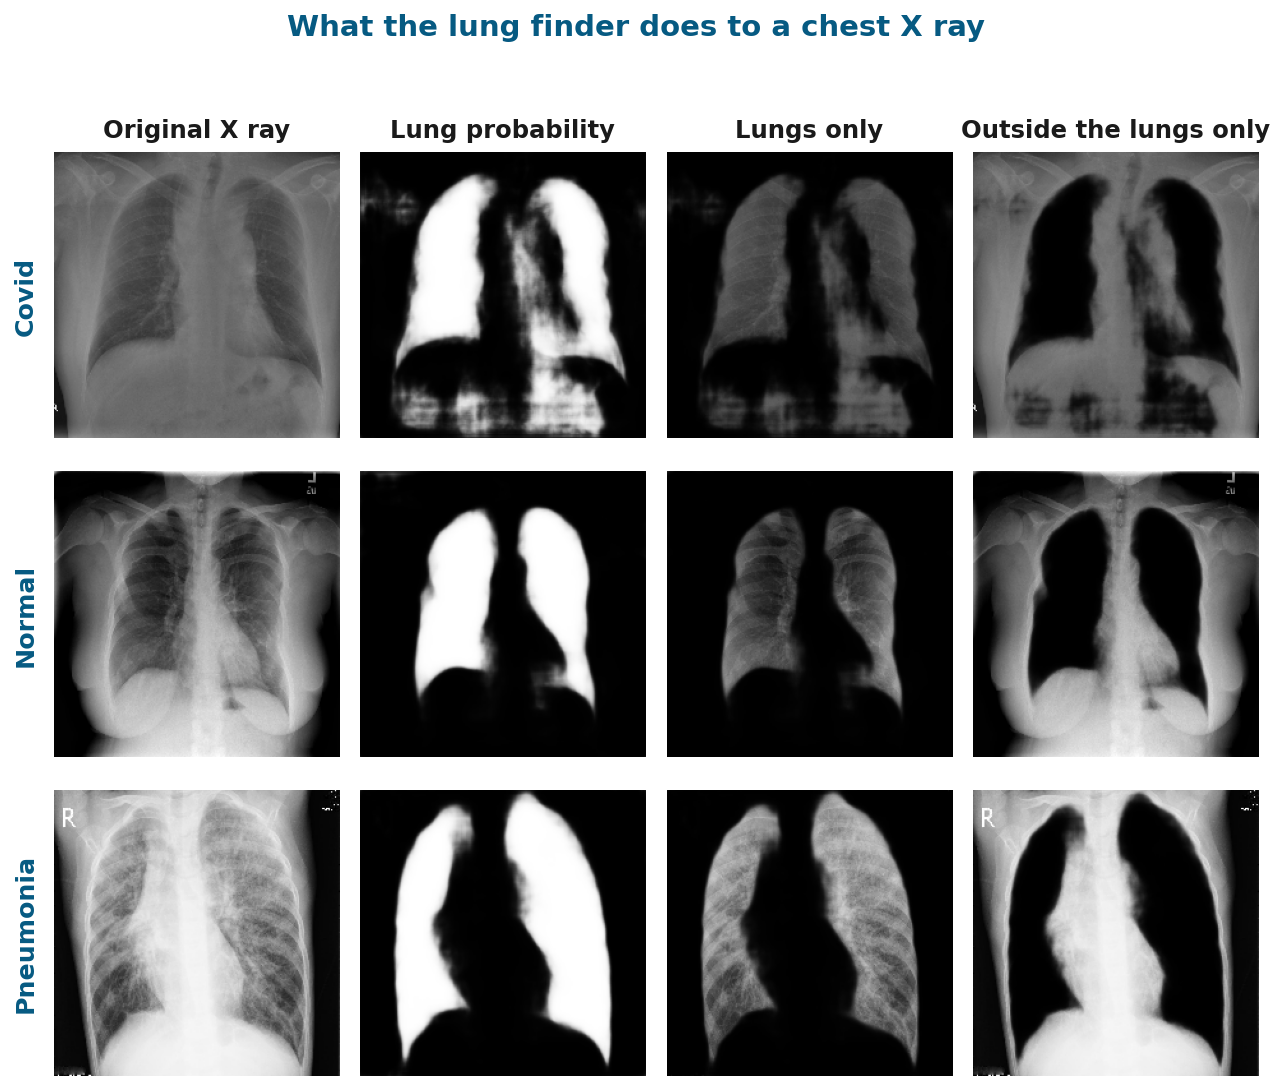

In [16]:
LUNG_DIR = "/content/lung_data"
%cd {REPO}
!python lung_focus.py --dataset {DATASET} --outdir {LUNG_DIR}
%cd /content
assert os.path.exists(f"{LUNG_DIR}/masks.npz"), "The lung finder did not finish. Read the messages printed above."
masks = lungs.load_masks(f"{LUNG_DIR}/masks.npz", DATASET, paths)
LUNG7, LUNG14 = lungs.lung_grid(masks, 7), lungs.lung_grid(masks, 14)
LUNG_AREA = float(LUNG7.mean())
print(f"On average, the lungs cover {LUNG_AREA:.0%} of the picture.")
display(Image(f"{LUNG_DIR}/lung_focus_preview.png"))

## 6. Frozen VGG19 features

In [17]:
# Blocks 1 to 4 never change, so their output (the input of block 5) is computed once for every image.
t0 = time.time()
F4, F5, B5W = models.extract_vgg19_stages(images, CONFIG["image_size"], CONFIG["weights"])
print(f"Block 5 input {F4.shape[1:]}, block 5 output {F5.shape[1:]}, {time.time() - t0:.0f} seconds.")
assert F4.shape[1] == LUNG14.shape[1] and F5.shape[1] == LUNG7.shape[1]

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Block 5 input (14, 14, 512), block 5 output (7, 7, 512), 111 seconds.


## 7. Reference models on the test set

* **File properties only:** a decision tree that never sees the picture.
* **Frozen baseline, frozen source weights, frozen lung guided:** the round 1 models, retrained here on the same split so that every comparison comes from one run.

In [18]:
RESULTS = {"test": [], "unseen": []}
PROBS = {"test": {}, "unseen": {}}
MODELS = {}
HISTORY = {}
W_TRAIN = train.source_weights(labels, weight_groups, tr)


def score(split_name, idx, model_name, seed, model, kind):
    if kind == "frozen":
        p, ev, cam = train.predict_grid_head(model, F5, idx, LUNG7)
        attr = None
    else:
        p, ev, cam, attr = train.predict_finetuned(model, F4, idx, LUNG7, LUNG14)
    row = {"model": model_name, "seed": seed}
    row.update(evaluate.set_metrics(labels[idx], p, coll[idx], CLASSES, ev, cam))
    if attr is not None:
        row["attribution inside lungs"] = float(np.nanmean(attr))
    RESULTS[split_name].append(row)
    PROBS[split_name][(model_name, seed)] = p
    return row


def stage1(seed, weights=None, lam=0.0):
    return train.fit_grid_head(F5, labels, tr, LUNG7, N_CLASSES, lam=lam, sample_weight=weights,
                               epochs=CONFIG["head_epochs"], batch=CONFIG["batch"], seed=seed)[0]


def stage2(head, seed, lam=0.0, weights=None):
    top = models.finetune_top(B5W, N_CLASSES)
    models.copy_head(head, top)
    ft = CONFIG["finetune"]
    return train.fine_tune_guided(top, F4, labels, tr, te, LUNG7, LUNG14, lam=lam, sample_weight=weights,
                                  epochs=ft["epochs"], batch=CONFIG["batch"], lr=ft["lr"], seed=seed, coll=coll, classes=CLASSES)


def report(model_name, seed, row, seconds):
    print(f"{model_name} | seed {seed}: test accuracy {row['accuracy']:.1%}, PNG pneumonia recall {row['pneumonia recall, PNG']:.1%}, "
          f"PNG AUC {row['normal vs pneumonia AUC, PNG']:.3f}, Grad CAM in lungs {row['Grad CAM heat inside lungs']:.0%}, {seconds:.0f} s")


prop_feats = data.encode_properties(props)
tree = train.fit_tree(prop_feats, labels, tr, seed=0)
row = {"model": "file properties only", "seed": 0}
row.update(evaluate.set_metrics(labels[te], tree.predict_proba(prop_feats[te]), coll[te], CLASSES))
RESULTS["test"].append(row)

for s in CONFIG["seeds"]:
    t0 = time.time()
    model = stage1(s, lam=CONFIG["round1_lambda"])
    MODELS[("frozen lung guided", s)] = (model, "frozen")
    report("frozen lung guided", s, score("test", te, "frozen lung guided", s, model, "frozen"), time.time() - t0)

frozen lung guided | seed 0: test accuracy 93.1%, PNG pneumonia recall 7.7%, PNG AUC 0.589, Grad CAM in lungs 60%, 23 s
frozen lung guided | seed 1: test accuracy 93.1%, PNG pneumonia recall 7.7%, PNG AUC 0.546, Grad CAM in lungs 53%, 15 s
frozen lung guided | seed 2: test accuracy 94.3%, PNG pneumonia recall 3.8%, PNG AUC 0.550, Grad CAM in lungs 57%, 15 s


## 8. The modified block: fine tuning with lung guidance

Each fine tuned model is trained in two stages. Stage 1 trains the grid classifier on frozen features, exactly as in round 1, and is itself kept as the frozen version. Stage 2 then trains block 5 and the classifier together for up to 8 epochs, and keeps the epoch with the lowest test loss.

### 8a. Choosing the penalty strength on the test set

In [19]:
sweep = []
s = CONFIG["sweep_seed"]
head = stage1(s)
for lam in [0] + CONFIG["lambdas"]:
    t0 = time.time()
    top, hist = stage2(head, s, lam=lam)
    p, ev, cam, attr = train.predict_finetuned(top, F4, te, LUNG7, LUNG14)
    r = {"lambda": lam, "best epoch": hist["best epoch"], "seconds per epoch": np.mean(hist["seconds"])}
    r.update(evaluate.set_metrics(labels[te], p, coll[te], CLASSES, ev, cam))
    r["attribution inside lungs"] = float(np.nanmean(attr))
    sweep.append(r)
    print(f"lambda {lam}: test accuracy {r['accuracy']:.1%}, PNG AUC {r['normal vs pneumonia AUC, PNG']:.3f}, "
          f"attribution in lungs {r['attribution inside lungs']:.0%}, {time.time() - t0:.0f} s")
    del top
sweep = pd.DataFrame(sweep).set_index("lambda")
display(sweep[["best epoch", "seconds per epoch", "accuracy", "pneumonia recall, PNG", "normal vs pneumonia AUC, PNG",
               "evidence inside lungs", "Grad CAM heat inside lungs", "attribution inside lungs"]].round(3))

ok = [lam for lam in CONFIG["lambdas"] if sweep.loc[lam, "accuracy"] >= sweep.loc[0, "accuracy"] - CONFIG["max_accuracy_drop"]]
CHOSEN_LAMBDA = max(ok, key=lambda lam: sweep.loc[lam, "normal vs pneumonia AUC, PNG"]) if ok else min(CONFIG["lambdas"])
print("Chosen penalty strength:", CHOSEN_LAMBDA)

lambda 0: test accuracy 95.5%, PNG AUC 0.691, attribution in lungs 31%, 99 s
lambda 1: test accuracy 96.4%, PNG AUC 0.722, attribution in lungs 80%, 158 s
lambda 5: test accuracy 95.8%, PNG AUC 0.655, attribution in lungs 85%, 151 s


,best epoch,seconds per epoch,accuracy,"pneumonia recall, PNG","normal vs pneumonia AUC, PNG",evidence inside lungs,Grad CAM heat inside lungs,attribution inside lungs
lambda,,,,,,,,
0,1,11.838,0.955,0.077,0.691,0.201,0.217,0.311
1,3,19.244,0.964,0.038,0.722,0.209,0.140,0.800
5,1,18.310,0.958,0.115,0.655,0.205,0.127,0.851


Chosen penalty strength: 1


### 8b. Fine tuned versions, three seeds each

In [20]:
for s in CONFIG["seeds"]:
    plain_head = stage1(s)
    weighted_head = stage1(s, weights=W_TRAIN)
    for name, head in [("frozen baseline", plain_head), ("frozen source weights", weighted_head)]:
        MODELS[(name, s)] = (head, "frozen")
        report(name, s, score("test", te, name, s, head, "frozen"), 0)
    for name, head, lam, w in [("fine tuned baseline", plain_head, 0.0, None),
                               ("fine tuned source weights", weighted_head, 0.0, W_TRAIN),
                               ("fine tuned lung guided", plain_head, CHOSEN_LAMBDA, None),
                               ("fine tuned lung guided + source weights", weighted_head, CHOSEN_LAMBDA, W_TRAIN)]:
        t0 = time.time()
        top, hist = stage2(head, s, lam=lam, weights=w)
        MODELS[(name, s)] = (top, "finetuned")
        HISTORY[(name, s)] = hist
        report(name, s, score("test", te, name, s, top, "finetuned"), time.time() - t0)

frozen baseline | seed 0: test accuracy 95.0%, PNG pneumonia recall 7.7%, PNG AUC 0.723, Grad CAM in lungs 23%, 0 s
frozen source weights | seed 0: test accuracy 93.5%, PNG pneumonia recall 30.8%, PNG AUC 0.712, Grad CAM in lungs 23%, 0 s
fine tuned baseline | seed 0: test accuracy 96.4%, PNG pneumonia recall 15.4%, PNG AUC 0.799, Grad CAM in lungs 20%, 97 s
fine tuned source weights | seed 0: test accuracy 96.3%, PNG pneumonia recall 19.2%, PNG AUC 0.791, Grad CAM in lungs 20%, 98 s
fine tuned lung guided | seed 0: test accuracy 95.9%, PNG pneumonia recall 0.0%, PNG AUC 0.750, Grad CAM in lungs 20%, 157 s
fine tuned lung guided + source weights | seed 0: test accuracy 93.9%, PNG pneumonia recall 46.2%, PNG AUC 0.805, Grad CAM in lungs 18%, 159 s
frozen baseline | seed 1: test accuracy 93.5%, PNG pneumonia recall 3.8%, PNG AUC 0.645, Grad CAM in lungs 23%, 0 s
frozen source weights | seed 1: test accuracy 94.0%, PNG pneumonia recall 15.4%, PNG AUC 0.665, Grad CAM in lungs 24%, 0 s
fine

In [21]:
ORDER = ["frozen baseline", "frozen source weights", "frozen lung guided", "fine tuned baseline", "fine tuned source weights",
         "fine tuned lung guided", "fine tuned lung guided + source weights"]
SHOW = ["accuracy", "macro AUC", "covid recall", "pneumonia recall, PNG", "normal recall, PNG", "pneumonia recall, JPEG",
        "normal recall, JPEG", "normal vs pneumonia AUC, PNG", "normal vs pneumonia AUC, JPEG", "evidence inside lungs",
        "Grad CAM heat inside lungs", "attribution inside lungs"]


def results_table(split_name):
    rows = [r for r in RESULTS[split_name] if r["model"] != "file properties only"]
    t = evaluate.summarize(rows, order=ORDER)
    return t[[c for c in SHOW if c in t.columns]]


print("Test set, file properties only:")
display(pd.DataFrame([r for r in RESULTS["test"] if r["model"] == "file properties only"]).set_index("model")[SHOW[:9]].round(3))
print(f"Test set, VGG19 (mean ± standard deviation over {len(CONFIG['seeds'])} seeds). Lungs cover {LUNG_AREA:.0%} of the picture.")
display(results_table("test"))

Test set, file properties only:


,accuracy,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, PNG","normal vs pneumonia AUC, JPEG"
model,,,,,,,,,
file properties only,0.968,0.984,0.983,0.0,1.0,0.997,1.0,0.498,0.999


Test set, VGG19 (mean ± standard deviation over 3 seeds). Lungs cover 23% of the picture.


,accuracy,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, PNG","normal vs pneumonia AUC, JPEG",evidence inside lungs,Grad CAM heat inside lungs,attribution inside lungs
frozen baseline,94.8 ± 1.2,0.989 ± 0.001,94.9 ± 3.8,5.1 ± 2.2,97.9 ± 2.0,99.2 ± 1.2,94.0 ± 4.0,0.689 ± 0.040,0.999 ± 0.000,21.7 ± 0.6,23.3 ± 0.1,nan ± nan
frozen source weights,94.1 ± 0.7,0.988 ± 0.001,94.9 ± 2.6,23.1 ± 7.7,93.9 ± 0.6,99.2 ± 0.5,94.7 ± 3.1,0.695 ± 0.026,0.998 ± 0.001,21.4 ± 0.6,23.1 ± 0.4,nan ± nan
frozen lung guided,93.5 ± 0.7,0.983 ± 0.001,94.1 ± 0.4,6.4 ± 2.2,94.7 ± 2.5,99.1 ± 0.5,91.3 ± 4.2,0.562 ± 0.024,0.998 ± 0.001,54.4 ± 0.1,56.7 ± 3.1,nan ± nan
fine tuned baseline,96.3 ± 0.1,0.991 ± 0.002,98.0 ± 0.5,9.0 ± 5.9,98.3 ± 1.0,99.5 ± 0.2,98.0 ± 2.0,0.735 ± 0.066,1.000 ± 0.000,20.2 ± 0.5,20.8 ± 0.9,42.4 ± 8.6
fine tuned source weights,95.8 ± 1.0,0.991 ± 0.002,97.4 ± 0.9,15.4 ± 3.8,97.6 ± 0.6,98.9 ± 1.7,96.7 ± 1.2,0.749 ± 0.039,0.999 ± 0.000,20.2 ± 0.5,20.3 ± 0.4,37.5 ± 8.5
fine tuned lung guided,96.0 ± 0.2,0.991 ± 0.001,98.9 ± 0.6,7.7 ± 10.2,97.2 ± 0.8,99.0 ± 0.4,94.7 ± 2.3,0.739 ± 0.014,0.996 ± 0.005,21.9 ± 1.8,18.9 ± 2.7,72.1 ± 7.9
fine tuned lung guided + source weights,92.4 ± 3.0,0.988 ± 0.004,97.6 ± 3.2,32.1 ± 15.5,84.7 ± 6.9,98.1 ± 0.8,97.3 ± 3.1,0.721 ± 0.077,0.999 ± 0.000,21.1 ± 0.8,18.9 ± 1.5,60.6 ± 11.0


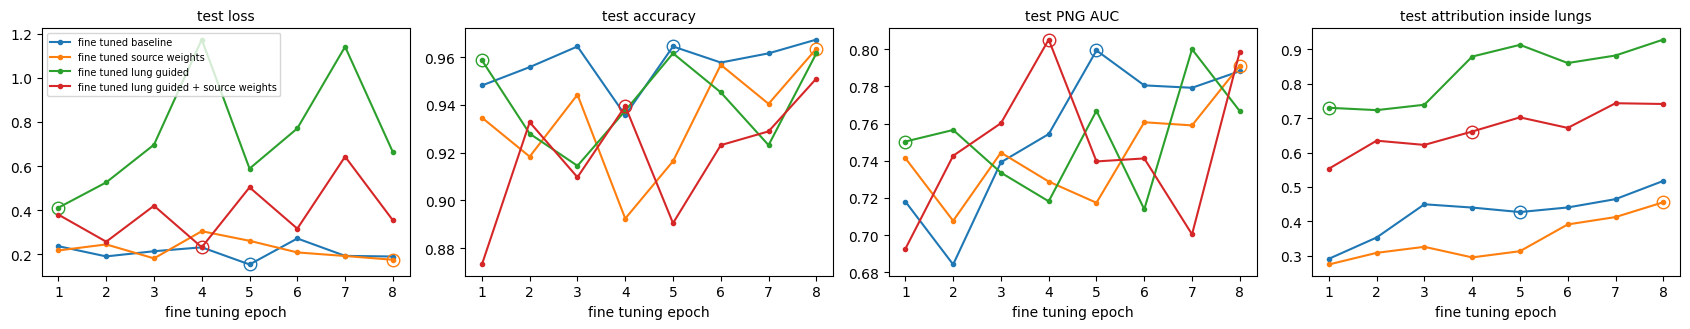

In [22]:
# Stage 2 curves for the first seed of every fine tuned version. The dot marks the kept epoch.
keys = ["test loss", "test accuracy", "test PNG AUC", "test attribution inside lungs"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for name in ORDER[3:]:
    h = HISTORY[(name, CONFIG["seeds"][0])]
    for ax, k in zip(axes, keys):
        x = np.arange(1, len(h[k]) + 1)
        line, = ax.plot(x, h[k], marker=".", label=name)
        ax.plot(h["best epoch"], h[k][h["best epoch"] - 1], "o", ms=9, mfc="none", c=line.get_color())
for ax, k in zip(axes, keys):
    ax.set_title(k, fontsize=10)
    ax.set_xlabel("fine tuning epoch")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

Grad CAM heat on the 7 by 7 output of block 5


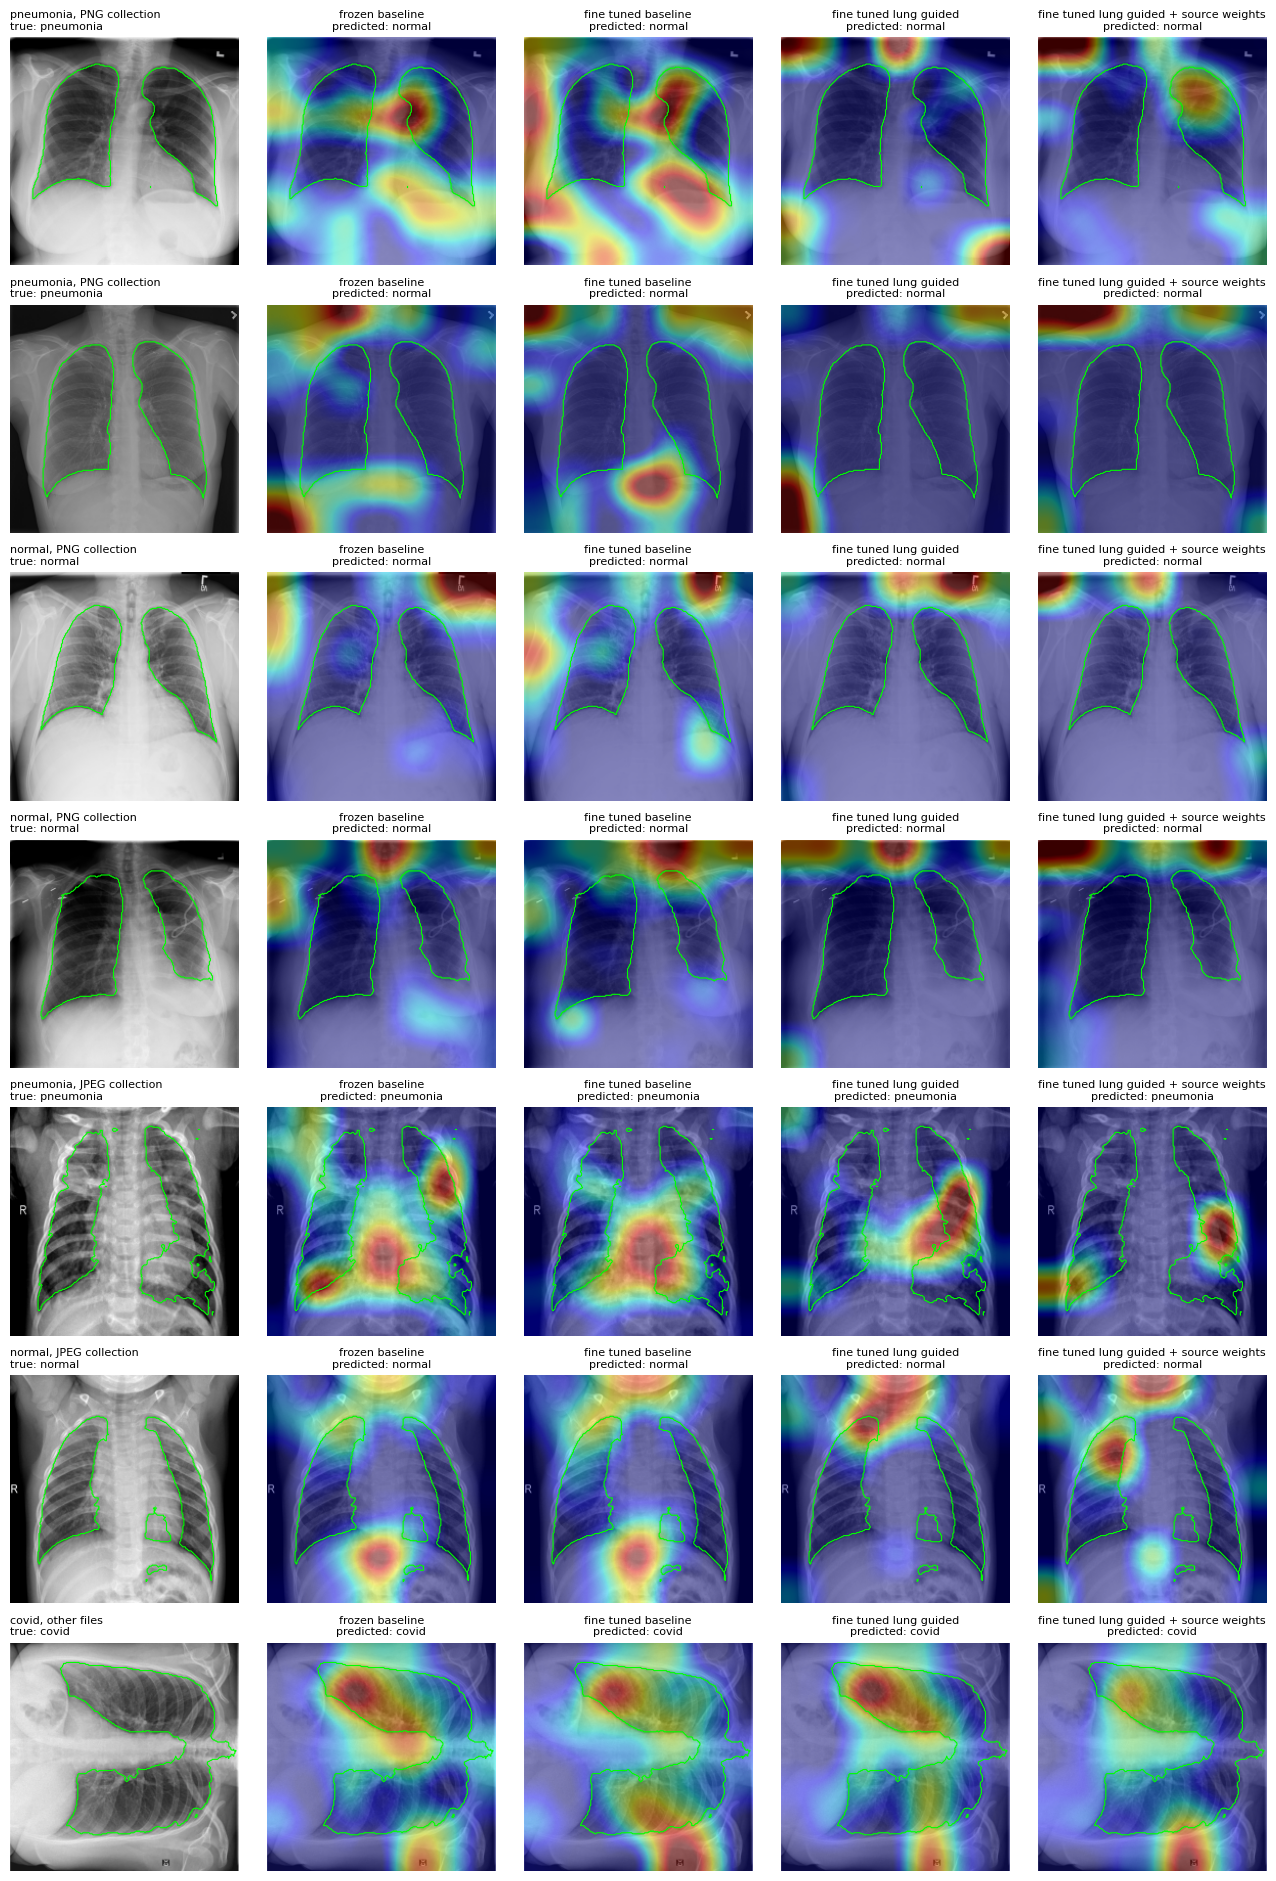

Attribution on the 14 by 14 input of block 5 (what the lung guided penalty measures)


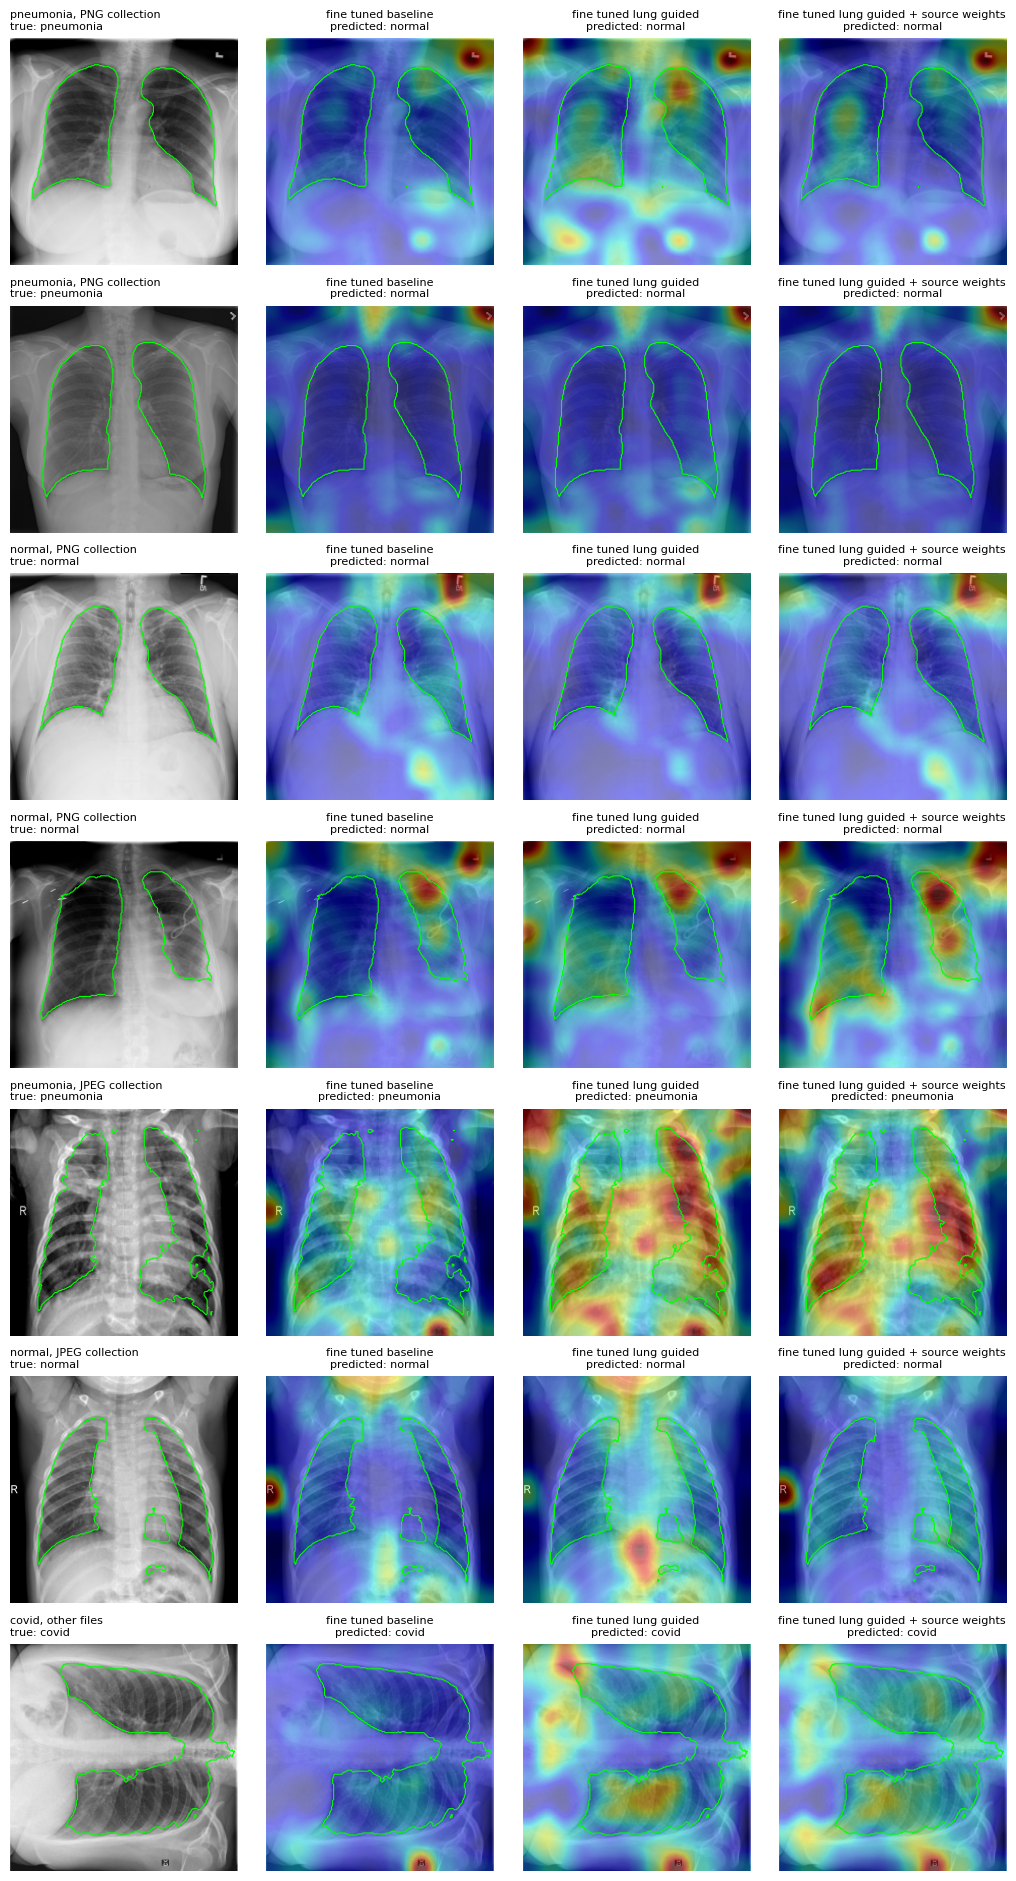

In [23]:
# Where each model looks on the same test images (first seed). The green line is the lung outline.
rng = np.random.RandomState(0)
pick, titles = [], []
for cls, col, k in [("pneumonia", "PNG collection", 2), ("normal", "PNG collection", 2), ("pneumonia", "JPEG collection", 1),
                    ("normal", "JPEG collection", 1), ("covid", None, 1)]:
    cand = [i for i in te if CLASSES[labels[i]] == cls and (col is None or coll[i] == col)]
    for i in rng.choice(cand, min(k, len(cand)), replace=False):
        pick.append(i)
        titles.append(f"{cls}, {coll[i]}")
pick = np.array(pick)
s0 = CONFIG["seeds"][0]
cams, attrs, probs = {}, {}, {}
cams["frozen baseline"], probs["frozen baseline"] = train.gradcam_maps(MODELS[("frozen baseline", s0)][0], F5, pick)
for name in ["fine tuned baseline", "fine tuned lung guided", "fine tuned lung guided + source weights"]:
    cams[name], attrs[name], probs[name] = train.finetuned_maps(MODELS[(name, s0)][0], F4, pick)
print("Grad CAM heat on the 7 by 7 output of block 5")
evaluate.show_heatmaps(images, masks, pick, cams, probs, labels, CLASSES, titles)
print("Attribution on the 14 by 14 input of block 5 (what the lung guided penalty measures)")
evaluate.show_heatmaps(images, masks, pick, attrs, {k: probs[k] for k in attrs}, labels, CLASSES, titles)

## 9. Unseen set

Every model above is scored once on the unseen images, with no further changes. This is the second look at the unseen set.

In [24]:
row = {"model": "file properties only", "seed": 0}
row.update(evaluate.set_metrics(labels[unseen], tree.predict_proba(prop_feats[unseen]), coll[unseen], CLASSES))
RESULTS["unseen"].append(row)
for (name, s), (model, kind) in MODELS.items():
    score("unseen", unseen, name, s, model, kind)
print("Unseen set, file properties only:")
display(pd.DataFrame([r for r in RESULTS["unseen"] if r["model"] == "file properties only"]).set_index("model")[SHOW[:9]].round(3))
print(f"Unseen set, VGG19 (mean ± standard deviation over {len(CONFIG['seeds'])} seeds).")
display(results_table("unseen"))

Unseen set, file properties only:


,accuracy,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, PNG","normal vs pneumonia AUC, JPEG"
model,,,,,,,,,
file properties only,0.959,0.98,0.977,0.0,1.0,0.981,0.96,0.502,0.988


Unseen set, VGG19 (mean ± standard deviation over 3 seeds).


,accuracy,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, PNG","normal vs pneumonia AUC, JPEG",evidence inside lungs,Grad CAM heat inside lungs,attribution inside lungs
frozen baseline,94.3 ± 1.0,0.987 ± 0.001,97.3 ± 1.0,9.9 ± 7.7,96.1 ± 5.1,97.3 ± 1.6,90.0 ± 10.0,0.656 ± 0.028,0.996 ± 0.000,21.8 ± 0.6,23.3 ± 0.0,nan ± nan
frozen source weights,92.6 ± 0.4,0.986 ± 0.001,97.5 ± 0.7,24.7 ± 5.7,87.5 ± 2.9,97.8 ± 1.1,92.0 ± 5.3,0.645 ± 0.029,0.996 ± 0.001,21.5 ± 0.5,23.1 ± 0.2,nan ± nan
frozen lung guided,93.0 ± 0.2,0.983 ± 0.001,96.8 ± 1.3,4.9 ± 2.1,93.7 ± 3.0,96.5 ± 1.6,86.7 ± 5.0,0.585 ± 0.041,0.990 ± 0.002,54.3 ± 0.1,56.3 ± 3.4,nan ± nan
fine tuned baseline,95.3 ± 1.1,0.989 ± 0.001,98.8 ± 0.8,3.7 ± 3.7,96.4 ± 3.6,98.8 ± 0.8,90.7 ± 5.0,0.672 ± 0.019,0.997 ± 0.001,20.3 ± 0.4,20.8 ± 1.0,42.2 ± 8.3
fine tuned source weights,94.8 ± 0.8,0.989 ± 0.002,98.5 ± 0.6,14.8 ± 11.1,95.4 ± 1.6,97.2 ± 2.7,94.7 ± 5.0,0.679 ± 0.030,0.997 ± 0.001,20.3 ± 0.5,20.5 ± 0.4,37.6 ± 7.9
fine tuned lung guided,94.3 ± 0.6,0.989 ± 0.000,98.5 ± 1.7,8.6 ± 9.3,95.0 ± 3.6,97.4 ± 1.0,87.3 ± 9.9,0.685 ± 0.016,0.989 ± 0.013,22.0 ± 1.7,20.0 ± 3.4,71.0 ± 7.0
fine tuned lung guided + source weights,90.9 ± 2.4,0.984 ± 0.006,98.8 ± 1.3,25.9 ± 9.8,80.4 ± 7.6,97.3 ± 1.3,92.7 ± 9.5,0.640 ± 0.053,0.997 ± 0.002,21.2 ± 0.8,18.9 ± 1.7,60.8 ± 10.9


In [25]:
KEY = ["accuracy", "pneumonia recall, PNG", "normal recall, JPEG", "normal vs pneumonia AUC, PNG"]
y_u, c_u = labels[unseen], coll[unseen]
avg = {name: np.mean([PROBS["unseen"][(name, s)] for s in CONFIG["seeds"]], axis=0) for name in ORDER}

rows = {}
for name in ORDER:
    point = evaluate.set_metrics(y_u, avg[name], c_u, CLASSES)
    ci = evaluate.bootstrap(y_u, avg[name], c_u, CLASSES, KEY, n=CONFIG["bootstrap"], seed=0)
    rows[name] = {m: f"{point[m]:.3f} [{ci[m][0]:.3f}, {ci[m][1]:.3f}]" for m in KEY}
print("Unseen set, seeds averaged: value [95 percent interval]")
display(pd.DataFrame(rows).T)

pairs = [("fine tuned baseline", "frozen baseline"), ("fine tuned source weights", "fine tuned baseline"),
         ("fine tuned lung guided", "fine tuned baseline"),
         ("fine tuned lung guided + source weights", "fine tuned baseline"), ("fine tuned lung guided", "frozen lung guided")]
diff = {}
for new, old in pairs:
    d = evaluate.bootstrap_difference(y_u, avg[new], avg[old], c_u, CLASSES, KEY, n=CONFIG["bootstrap"], seed=1)
    diff[f"{new} minus {old}"] = {m: f"[{d[m][0]:+.3f}, {d[m][1]:+.3f}]" for m in KEY}
print("Unseen set: 95 percent interval of the difference. An interval fully above zero is a clear gain, fully below zero a clear loss.")
display(pd.DataFrame(diff).T)

Unseen set, seeds averaged: value [95 percent interval]


,accuracy,"pneumonia recall, PNG","normal recall, JPEG","normal vs pneumonia AUC, PNG"
frozen baseline,"0.952 [0.939, 0.965]","0.037 [0.000, 0.120]","0.940 [0.867, 1.000]","0.661 [0.548, 0.752]"
frozen source weights,"0.934 [0.919, 0.948]","0.259 [0.091, 0.429]","0.940 [0.867, 1.000]","0.652 [0.529, 0.748]"
frozen lung guided,"0.935 [0.918, 0.951]","0.037 [0.000, 0.120]","0.880 [0.783, 0.961]","0.583 [0.466, 0.696]"
fine tuned baseline,"0.961 [0.949, 0.973]","0.037 [0.000, 0.120]","0.940 [0.867, 1.000]","0.691 [0.579, 0.784]"
fine tuned source weights,"0.956 [0.942, 0.967]","0.111 [0.000, 0.238]","0.960 [0.896, 1.000]","0.691 [0.590, 0.777]"
fine tuned lung guided,"0.953 [0.940, 0.965]","0.037 [0.000, 0.120]","0.940 [0.865, 1.000]","0.673 [0.552, 0.770]"
fine tuned lung guided + source weights,"0.922 [0.907, 0.937]","0.259 [0.091, 0.435]","0.960 [0.904, 1.000]","0.628 [0.505, 0.733]"


Unseen set: 95 percent interval of the difference. An interval fully above zero is a clear gain, fully below zero a clear loss.


,accuracy,"pneumonia recall, PNG","normal recall, JPEG","normal vs pneumonia AUC, PNG"
fine tuned baseline minus frozen baseline,"[+0.002, +0.015]","[+0.000, +0.000]","[-0.056, +0.058]","[-0.015, +0.078]"
fine tuned source weights minus fine tuned baseline,"[-0.012, +0.003]","[+0.000, +0.192]","[+0.000, +0.068]","[-0.061, +0.058]"
fine tuned lung guided minus fine tuned baseline,"[-0.016, +0.002]","[+0.000, +0.000]","[-0.059, +0.052]","[-0.084, +0.044]"
fine tuned lung guided + source weights minus fine tuned baseline,"[-0.053, -0.025]","[+0.074, +0.409]","[-0.048, +0.085]","[-0.133, -0.002]"
fine tuned lung guided minus frozen lung guided,"[+0.006, +0.031]","[+0.000, +0.000]","[-0.022, +0.148]","[-0.031, +0.203]"


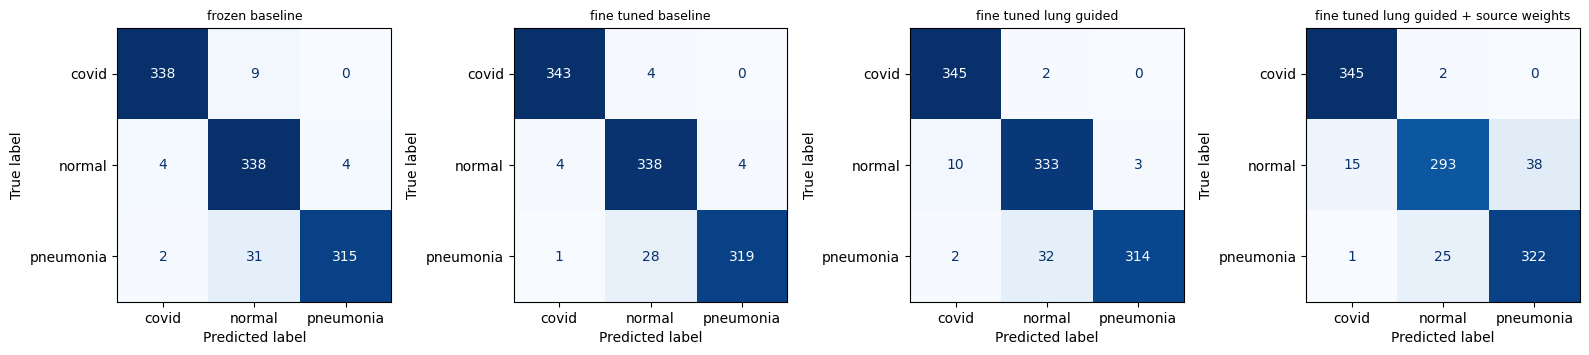

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, name in zip(axes, ["frozen baseline", "fine tuned baseline", "fine tuned lung guided", "fine tuned lung guided + source weights"]):
    evaluate.confusion_from_probs(y_u, avg[name], CLASSES, name, ax)
plt.tight_layout()
plt.show()

## 10. Summary: round 1 and round 2 on the unseen set (VGG19)

In [27]:
cols = ["accuracy", "pneumonia recall, PNG", "normal recall, JPEG", "normal vs pneumonia AUC, PNG", "Grad CAM heat inside lungs"]
r1 = pd.DataFrame(ROUND1_UNSEEN_VGG19).T
r1 = r1.apply(lambda c: c.map(lambda v: f"{v:.3f}" if c.name == "normal vs pneumonia AUC, PNG" else f"{v:.1f}"))
r2 = results_table("unseen")[cols]
r2.index = [f"{i} (round 2)" for i in r2.index]
display(pd.concat([r1[cols], r2]))
print(f"Lungs cover {LUNG_AREA:.0%} of the picture. Chosen penalty strength for fine tuning: {CHOSEN_LAMBDA}.")
print(f"Total run time: {(time.time() - RUN_START) / 60:.0f} minutes.")

,accuracy,"pneumonia recall, PNG","normal recall, JPEG","normal vs pneumonia AUC, PNG",Grad CAM heat inside lungs
frozen baseline (round 1),94.4,9.9,89.3,0.656,23.3
frozen source weights (round 1),92.6,24.7,90.7,0.646,23.1
frozen lung guided (round 1),93.1,4.9,88.0,0.586,56.2
frozen lung guided + source weights (round 1),92.0,19.8,92.7,0.644,45.1
frozen baseline (round 2),94.3 ± 1.0,9.9 ± 7.7,90.0 ± 10.0,0.656 ± 0.028,23.3 ± 0.0
frozen source weights (round 2),92.6 ± 0.4,24.7 ± 5.7,92.0 ± 5.3,0.645 ± 0.029,23.1 ± 0.2
frozen lung guided (round 2),93.0 ± 0.2,4.9 ± 2.1,86.7 ± 5.0,0.585 ± 0.041,56.3 ± 3.4
fine tuned baseline (round 2),95.3 ± 1.1,3.7 ± 3.7,90.7 ± 5.0,0.672 ± 0.019,20.8 ± 1.0
fine tuned source weights (round 2),94.8 ± 0.8,14.8 ± 11.1,94.7 ± 5.0,0.679 ± 0.030,20.5 ± 0.4
fine tuned lung guided (round 2),94.3 ± 0.6,8.6 ± 9.3,87.3 ± 9.9,0.685 ± 0.016,20.0 ± 3.4


Lungs cover 23% of the picture. Chosen penalty strength for fine tuning: 1.
Total run time: 47 minutes.
